# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Arifin Ihsan Nugroho
- **Email:** ds183b6y0241@student.devacademy.id
- **ID Dicoding:** DS183B6Y0241

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Berdasarkan eksplorasi permasalahan pada operasional sistem penyewaan sepeda (*Bike Sharing Dataset*), berikut adalah 2 pertanyaan bisnis terstruktur yang dirumuskan menggunakan prinsip **SMART (Specific, Measurable, Action-oriented, Relevant, Time-bound)**:

- **Pertanyaan 1:** Bagaimana pengaruh pergantian musim (*season*) dan kondisi cuaca (*weather situation*) terhadap rata-rata jumlah penyewaan sepeda harian (*cnt*) pada periode 2011–2012?
  - **Specific:** Fokus pada pengaruh faktor lingkungan (musim dan cuaca) terhadap fluktuasi total volume peminjaman sepeda harian.
  - **Measurable:** Diukur dengan metrik kuantitatif: rata-rata, median, dan total peminjaman harian (*cnt*).
  - **Action-Oriented:** Memberikan acuan bagi manajemen dalam penyesuaian ketersediaan armada, penjadwalan pemeliharaan rutin pada musim sepi, serta penetapan strategi insentif/promosi pada cuaca tertentu.
  - **Relevant:** Karakteristik cuaca dan musim merupakan faktor eksternal paling dominan yang memengaruhi mobilitas bersepeda.
  - **Time-bound:** Dibatasi pada data historis 2 tahun penuh (Januari 2011 hingga Desember 2012).

- **Pertanyaan 2:** Bagaimana perbedaan pola penyewaan sepeda per jam (*hour*) antara hari kerja (*working day*) dan akhir pekan/hari libur (*weekend/holiday*), serta bagaimana karakteristik pengguna kasual (*casual*) dibandingkan pengguna terdaftar (*registered*)?
  - **Specific:** Membedakan jam-jam puncak peminjaman (*peak hours*) antara hari kerja dan hari libur, serta membandingkan perilaku pengguna komuter (*registered*) versus pengguna rekreasi (*casual*).
  - **Measurable:** Dihitung berdasarkan rata-rata jumlah peminjaman per jam untuk masing-masing kelompok pengguna (`casual`, `registered`, dan total `cnt`).
  - **Action-Oriented:** Mengoptimalkan distribusi dan penyeimbangan unit (*bike rebalancing*) antar stasiun transit komuter pada jam sibuk hari kerja, serta stasiun wisata/taman pada akhir pekan.
  - **Relevant:** Ketersediaan sepeda di stasiun yang tepat pada waktu yang tepat adalah kunci efisiensi operasional dan kepuasan pelanggan.
  - **Time-bound:** Dianalisis secara teragregasi per jam sepanjang tahun 2011–2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from IPython.display import display

# Konfigurasi style seaborn dan pandas
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Semua packages dan library berhasil diimpor!")

Semua packages dan library berhasil diimpor!


## Data Wrangling

### Gathering Data

#### Memuat Data day_df dan hour_df dari Folder Dataset

In [2]:
from IPython.display import display
# Menentukan path dataset agar kompatibel baik di lingkungan root, submission, maupun cloud
possible_day_paths = [
    'data/day.csv',
    'data/data_1.csv',
    'dataset/day.csv',
    'Dataset/day.csv',
    '../data/day.csv',
    '../Dataset/day.csv'
]
possible_hour_paths = [
    'data/hour.csv',
    'data/data_2.csv',
    'dataset/hour.csv',
    'Dataset/hour.csv',
    '../data/hour.csv',
    '../Dataset/hour.csv'
]

day_path = next((p for p in possible_day_paths if os.path.exists(p)), 'day.csv')
hour_path = next((p for p in possible_hour_paths if os.path.exists(p)), 'hour.csv')

# Membaca data CSV
day_df = pd.read_csv(day_path)
hour_df = pd.read_csv(hour_path)

print(f"Memuat dataset berhasil dari: {day_path} dan {hour_path}")
print(f"Dimensi day_df : {day_df.shape[0]} baris, {day_df.shape[1]} kolom")
print(f"Dimensi hour_df: {hour_df.shape[0]} baris, {hour_df.shape[1]} kolom")

print("\n--- 5 Baris Pertama day_df ---")
display(day_df.head())

print("\n--- 5 Baris Pertama hour_df ---")
display(hour_df.head())


Memuat dataset berhasil dari: data/day.csv dan data/hour.csv
Dimensi day_df : 731 baris, 16 kolom
Dimensi hour_df: 17379 baris, 17 kolom

--- 5 Baris Pertama day_df ---


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



--- 5 Baris Pertama hour_df ---


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset harian (`day_df`) memiliki 731 baris (mewakili 731 hari dari 1 Januari 2011 hingga 31 Desember 2012) dan 16 kolom.
- Dataset per jam (`hour_df`) memiliki 17.379 baris (mewakili pencatatan per jam selama 2 tahun) dan 17 kolom (tambahan kolom jam `hr`).
- Kedua dataset mencakup data tanggal, informasi kalender/musim, kondisi cuaca terukur (suhu, kelembaban, kecepatan angin), serta jumlah penyewaan oleh pengguna `casual`, `registered`, dan total `cnt`.

### Assessing Data

#### Menilai Struktur, Kelengkapan, dan Kualitas Data

In [3]:
from IPython.display import display
print("=" * 35, "PENILAIAN DATA DAY_DF", "=" * 35)
print("\n[1] Informasi Struktur Data day_df:")
day_df.info()

print("\n[2] Jumlah Missing Values day_df:")
print(day_df.isna().sum())

print("\n[3] Jumlah Data Duplikat day_df:", day_df.duplicated().sum())

print("\n[4] Ringkasan Statistik Parameter day_df:")
display(day_df.describe())

print("\n" + "=" * 35, "PENILAIAN DATA HOUR_DF", "=" * 35)
print("\n[1] Informasi Struktur Data hour_df:")
hour_df.info()

print("\n[2] Jumlah Missing Values hour_df:")
print(hour_df.isna().sum())

print("\n[3] Jumlah Data Duplikat hour_df:", hour_df.duplicated().sum())

print("\n[4] Ringkasan Statistik Parameter hour_df:")
display(hour_df.describe())

=================================== PENILAIAN DATA DAY_DF ===================================

[1] Informasi Struktur Data day_df:
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



=================================== PENILAIAN DATA HOUR_DF ===================================

[1] Informasi Struktur Data hour_df:
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-nul

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take (Solusi Penanganan Masalah):**
Berdasarkan proses *assessing data*, berikut adalah tindakan konkret pembersihan yang akan dilakukan:
1. **Menangani *Invalid Data Type*:** Mengonversi kolom `dteday` dari tipe `object` (string) menjadi tipe `datetime64[ns]` agar operasi pengurutan dan filter berbasis waktu dapat dilakukan secara akurat.
2. **Menangani *Inconsistent / Uninformative Category Encoding*:** Mengubah nilai numerik kode integer pada kolom `season`, `weathersit`, `yr`, `mnth`, `weekday`, dan `workingday` menjadi label deskriptif menggunakan kamus pemetaan (*mapping dictionary*) agar lebih informatif dan mudah diinterpretasikan oleh stakeholder bisnis.
3. **Menangani *Redundant Feature*:** Menghapus kolom `instant` karena nilainya hanya merupakan penomoran indeks baris yang duplikatif dengan indeks default DataFrame pandas.
4. **Menangani *Normalized Scale* untuk Interpretasi Aktual:** Mengembalikan nilai parameter cuaca (`temp`, `atemp`, `hum`, `windspeed`) ke skala pengukuran aslinya (°C, %, km/h) melalui de-normalisasi sesuai rumus pada Readme.txt.

**Insight:**
Dari hasil penilaian (*assessing data*) terhadap `day_df` dan `hour_df`, diperoleh temuan sebagai berikut:
1. **Missing Values:** Tidak ditemukan nilai kosong (*missing values*) pada seluruh kolom kedua dataset (semua kolom bernilai 731 non-null pada `day_df` dan 17.379 non-null pada `hour_df`).
2. **Duplicate Data:** Tidak ditemukan baris data yang duplikat (*0 duplicated rows*) pada kedua dataset.
3. **Permasalahan Teridentifikasi:**
   - *Invalid Data Type:* Kolom tanggal `dteday` masih bertipe `object` (string).
   - *Inconsistent/Uninformative Values:* Kolom-kolom kategorikal masih berupa angka numerik mentah sehingga kurang intuitif untuk analisis bisnis.
   - *Redundant Column:* Kolom `instant` tidak memberikan nilai analitik apa pun.
   - *Scaled Numeric Values:* Nilai temperatur, kelembaban, dan kecepatan angin berada dalam bentuk pecahan normalisasi [0, 1] sehingga perlu dikonversi ke satuan metrik aslinya.
4. **Statistik Deskriptif:** Rentang nilai target penyewaan (`cnt`) berada pada batas normal (antara 22 hingga 8.714 sewa/hari dengan rata-rata 4.504 sewa/hari), tanpa indikasi anomali sistemik yang merusak data.

### Cleaning Data

#### Memperbaiki Tipe Data, Mapping Kategori, dan Validasi Data

In [4]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Menghapus kolom instant yang redundan
day_df.drop(columns=['instant'], inplace=True, errors='ignore')
hour_df.drop(columns=['instant'], inplace=True, errors='ignore')

# 3. Kamus pemetaan (mapping dictionary) berdasarkan Readme.txt
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather/Heavy Rain'
}
year_mapping = {0: '2011', 1: '2012'}
month_mapping = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
weekday_mapping = {0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'}
workingday_mapping = {0: 'Weekend/Holiday', 1: 'Working Day'}

# Terapkan pemetaan pada day_df
day_df['season_label'] = day_df['season'].map(season_mapping)
day_df['weather_label'] = day_df['weathersit'].map(weather_mapping)
day_df['year_label'] = day_df['yr'].map(year_mapping)
day_df['month_label'] = day_df['mnth'].map(month_mapping)
day_df['weekday_label'] = day_df['weekday'].map(weekday_mapping)
day_df['workingday_label'] = day_df['workingday'].map(workingday_mapping)

# Terapkan pemetaan pada hour_df
hour_df['season_label'] = hour_df['season'].map(season_mapping)
hour_df['weather_label'] = hour_df['weathersit'].map(weather_mapping)
hour_df['year_label'] = hour_df['yr'].map(year_mapping)
hour_df['month_label'] = hour_df['mnth'].map(month_mapping)
hour_df['weekday_label'] = hour_df['weekday'].map(weekday_mapping)
hour_df['workingday_label'] = hour_df['workingday'].map(workingday_mapping)

# 4. Denormalisasi parameter cuaca untuk kemudahan pembacaan
day_df['temp_celsius'] = (day_df['temp'] * 41).round(2)
day_df['atemp_celsius'] = (day_df['atemp'] * 50).round(2)
day_df['humidity_pct'] = (day_df['hum'] * 100).round(2)
day_df['windspeed_kmh'] = (day_df['windspeed'] * 67).round(2)

hour_df['temp_celsius'] = (hour_df['temp'] * 41).round(2)
hour_df['atemp_celsius'] = (hour_df['atemp'] * 50).round(2)
hour_df['humidity_pct'] = (hour_df['hum'] * 100).round(2)
hour_df['windspeed_kmh'] = (hour_df['windspeed'] * 67).round(2)

print("Validasi hasil pembersihan data (day_df):")
print(day_df[['dteday', 'season_label', 'weather_label', 'year_label', 'temp_celsius', 'cnt']].head())

print("\nVerifikasi tipe data kolom dteday:")
print("day_df['dteday'] :", day_df['dteday'].dtype)
print("hour_df['dteday']:", hour_df['dteday'].dtype)

Validasi hasil pembersihan data (day_df):
      dteday season_label        weather_label year_label  temp_celsius   cnt
0 2011-01-01       Spring         Misty/Cloudy       2011         14.11   985
1 2011-01-02       Spring         Misty/Cloudy       2011         14.90   801
2 2011-01-03       Spring  Clear/Partly Cloudy       2011          8.05  1349
3 2011-01-04       Spring  Clear/Partly Cloudy       2011          8.20  1562
4 2011-01-05       Spring  Clear/Partly Cloudy       2011          9.31  1600

Verifikasi tipe data kolom dteday:
day_df['dteday'] : datetime64[us]
hour_df['dteday']: datetime64[us]


**Insight:**
- Tipe data kolom tanggal (`dteday`) berhasil diubah menjadi `datetime64[ns]` pada kedua DataFrame.
- Kolom kategorikal baru yang deskriptif telah berhasil dibuat tanpa menghilangkan data mentah aslinya.
- Kolom denormalisasi suhu (`temp_celsius`), kelembaban (`humidity_pct`), dan kecepatan angin (`windspeed_kmh`) siap digunakan untuk analisis yang lebih intuitif.
- Data kini dalam kondisi bersih (*clean*), konsisten, dan siap untuk tahap Exploratory Data Analysis (EDA).

## Exploratory Data Analysis (EDA)

### Eksplorasi Hubungan Variabel dan Karakteristik Pengguna

**Tujuan Tahapan EDA:**
1. Memahami sebaran dan ringkasan parameter statistik kunci (total penyewaan, pengguna terdaftar, dan pengguna kasual).
2. Mengukur tingkat pertumbuhan tahunan (*Year-over-Year Growth*) dari tahun 2011 ke 2012.
3. Menjawab pertanyaan bisnis 1 melalui analisis agregasi kelompok (*grouping & aggregation*) berdasarkan pergantian musim (*season*) dan kondisi cuaca (*weathersit*).
4. Menjawab pertanyaan bisnis 2 melalui analisis jam puncak (*peak hours*) dan perbandingan perilaku hari kerja vs akhir pekan/hari libur.

In [5]:
from IPython.display import display
# 1. Ringkasan statistik performa sewa harian
print("=" * 35, "STATISTIK PERFORMA PENYEWAAN", "=" * 35)
total_rental = day_df['cnt'].sum()
total_casual = day_df['casual'].sum()
total_registered = day_df['registered'].sum()

print(f"Total Seluruh Penyewaan Sepeda (2011-2012) : {total_rental:,} unit")
print(f"Total Pengguna Kasual (Casual)             : {total_casual:,} unit ({total_casual/total_rental*100:.2f}%)")
print(f"Total Pengguna Terdaftar (Registered)       : {total_registered:,} unit ({total_registered/total_rental*100:.2f}%)")

# 2. Pertumbuhan Tahunan (2011 vs 2012)
print("\n" + "=" * 35, "PERBANDINGAN PER TAHUN", "=" * 35)
yearly_summary = day_df.groupby('year_label')['cnt'].agg(['count', 'mean', 'sum']).reset_index()
yearly_summary['pertumbuhan_%'] = yearly_summary['sum'].pct_change() * 100
display(yearly_summary)

# 3. Analisis Pengaruh Musim (Season) terhadap Penyewaan Harian
print("\n" + "=" * 35, "PENYEWAAN BERDASARKAN MUSIM", "=" * 35)
season_summary = day_df.groupby('season_label')['cnt'].agg(
    jumlah_hari='count',
    rata_rata='mean',
    median='median',
    standar_deviasi='std',
    total_sewa='sum'
).reindex(['Spring', 'Summer', 'Fall', 'Winter']).reset_index()
display(season_summary)

# 4. Analisis Pengaruh Kondisi Cuaca (Weathersit) terhadap Penyewaan Harian
print("\n" + "=" * 35, "PENYEWAAN BERDASARKAN KONDISI CUACA", "=" * 35)
weather_summary = day_df.groupby('weather_label')['cnt'].agg(
    jumlah_hari='count',
    rata_rata='mean',
    median='median',
    total_sewa='sum'
).reset_index().sort_values(by='rata_rata', ascending=False)
display(weather_summary)

# 5. Analisis Perilaku Pengguna Berdasarkan Tipe Hari (Working Day vs Weekend/Holiday)
print("\n" + "=" * 35, "PENYEWAAN BERDASARKAN TIPE HARI", "=" * 35)
daytype_summary = day_df.groupby('workingday_label')[['casual', 'registered', 'cnt']].mean().reset_index()
display(daytype_summary)

# 6. Analisis Jam Puncak (Peak Hours) pada hour_df
print("\n" + "=" * 35, "JAM PUNCAK PADA HARI KERJA (TOP 5)", "=" * 35)
hourly_working = hour_df[hour_df['workingday'] == 1].groupby('hr')[['casual', 'registered', 'cnt']].mean().reset_index()
display(hourly_working.sort_values(by='cnt', ascending=False).head(5))

print("\n" + "=" * 35, "JAM PUNCAK PADA AKHIR PEKAN / LIBUR (TOP 5)", "=" * 35)
hourly_weekend = hour_df[hour_df['workingday'] == 0].groupby('hr')[['casual', 'registered', 'cnt']].mean().reset_index()
display(hourly_weekend.sort_values(by='cnt', ascending=False).head(5))

=================================== STATISTIK PERFORMA PENYEWAAN ===================================
Total Seluruh Penyewaan Sepeda (2011-2012) : 3,292,679 unit
Total Pengguna Kasual (Casual)             : 620,017 unit (18.83%)
Total Pengguna Terdaftar (Registered)       : 2,672,662 unit (81.17%)

=================================== PERBANDINGAN PER TAHUN ===================================


,year_label,count,mean,sum,pertumbuhan_%
0,2011,365,3405.761644,1243103,NaN
1,2012,366,5599.934426,2049576,64.875799



=================================== PENYEWAAN BERDASARKAN MUSIM ===================================


,season_label,jumlah_hari,rata_rata,median,standar_deviasi,total_sewa
0,Spring,181,2604.132597,2209.0,1399.942119,471348
1,Summer,184,4992.331522,4941.5,1695.977235,918589
2,Fall,188,5644.303191,5353.5,1459.800381,1061129
3,Winter,178,4728.162921,4634.5,1699.615261,841613



=================================== PENYEWAAN BERDASARKAN KONDISI CUACA ===================================


,weather_label,jumlah_hari,rata_rata,median,total_sewa
0,Clear/Partly Cloudy,463,4876.786177,4844.0,2257952
2,Misty/Cloudy,247,4035.862348,4040.0,996858
1,Light Snow/Rain,21,1803.285714,1817.0,37869


... (2 outputs left out)


=================================== JAM PUNCAK PADA HARI KERJA (TOP 5) ===================================


,hr,casual,registered,cnt
17,17,56.895792,468.394790,525.290581
18,18,50.451807,441.775100,492.226908
8,8,22.264113,454.741935,477.006048
19,19,41.022088,307.379518,348.401606
16,16,48.344689,244.777555,293.122244



=================================== JAM PUNCAK PADA AKHIR PEKAN / LIBUR (TOP 5) ===================================


,hr,casual,registered,cnt
13,13,136.424242,236.307359,372.731602
12,12,126.246753,240.012987,366.259740
14,14,139.593074,225.051948,364.645022
15,15,136.502165,222.311688,358.813853
16,16,128.614719,224.112554,352.727273


**Insight:**
1. **Dominasi Pengguna Terdaftar (*Registered*):** Dari total 3.292.679 transaksi penyewaan sepeda sepanjang 2011–2012, mayoritas besar (81,17% atau 2.672.662 penyewaan) dilakukan oleh pengguna terdaftar. Pengguna kasual (*casual*) menyumbang 18,83% (620.017 penyewaan).
2. **Pertumbuhan Signifikan Tahun 2012:** Terjadi lonjakan volume penyewaan sebesar 64,88% dari tahun 2011 (1.243.103 unit) ke tahun 2012 (2.049.576 unit), mengindikasikan adopsi layanan bike-sharing yang semakin matang dan populer.
3. **Pengaruh Musim (*Season*):**
   - **Musim Gugur (*Fall*)** mencatat rata-rata sewa harian tertinggi yaitu **5.644 unit/hari** (total 1.061.129 penyewaan), disusul oleh **Musim Panas (*Summer*)** dengan **4.992 unit/hari**.
   - **Musim Semi (*Spring*)** mencatat performa sewa terendah secara drastis dengan rata-rata hanya **2.604 unit/hari** (total 471.348 penyewaan), kemungkinan besar akibat suhu awal tahun yang masih dingin membekukan.
4. **Pengaruh Kondisi Cuaca (*Weather*):**
   - Hari dengan cuaca **Cerah / Sedikit Berawan (*Clear/Partly Cloudy*)** adalah kondisi paling diminati pengguna dengan rata-rata **4.877 unit/hari** (total 2.257.952 penyewaan).
   - Cuaca **Berkabut / Mendung (*Misty/Cloudy*)** masih memiliki permintaan cukup kuat (rata-rata **4.036 unit/hari**).
   - Cuaca **Hujan/Salju Ringan (*Light Snow/Rain*)** menurunkan permintaan drastis menjadi **1.803 unit/hari** (turun >63% dibanding hari cerah).
5. **Pola Jam Berdasarkan Tipe Hari:**
   - **Hari Kerja (*Working Day*):** Terlihat pola dua puncak jam sibuk (*bimodal distribution*), yaitu pada pukul **08:00** (rata-rata 477 unit/jam) dan pukul **17:00–18:00** (rata-rata 492–525 unit/jam), yang sangat didominasi oleh pengguna komuter terdaftar.
   - **Akhir Pekan/Libur (*Weekend/Holiday*):** Terlihat pola kurva tunggal (*unimodal*) di mana puncak penggunaan terjadi pada siang hari antara pukul **12:00 hingga 15:00** (rata-rata 358–373 unit/jam), dengan lonjakan signifikan pada pengguna kasual (*casual*).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana pengaruh kondisi cuaca dan pergantian musim terhadap jumlah penyewaan sepeda harian?

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


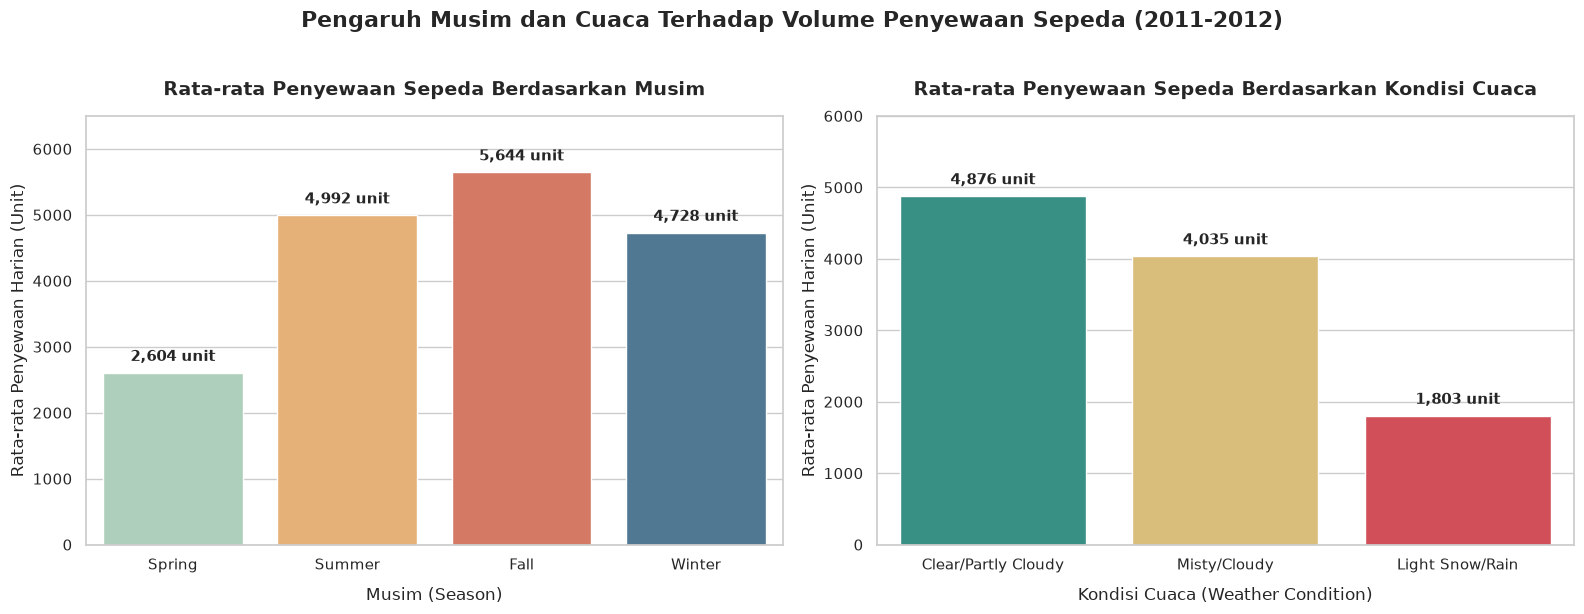

In [6]:
# Visualisasi untuk Pertanyaan 1
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Subplot 1: Rata-rata Penyewaan Berdasarkan Musim
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_palette = ['#A8D5BA', '#F7B267', '#E76F51', '#457B9D']

sns.barplot(
    data=day_df,
    x='season_label',
    y='cnt',
    order=season_order,
    palette=season_palette,
    estimator=np.mean,
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Rata-rata Penyewaan Sepeda Berdasarkan Musim', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Musim (Season)', fontsize=12, labelpad=10)
axes[0].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=12)
axes[0].set_ylim(0, 6500)

# Tambahkan label angka di atas setiap bar
for p in axes[0].patches:
    val = int(p.get_height())
    axes[0].annotate(
        f'{val:,} unit',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=11, fontweight='semibold',
        xytext=(0, 6), textcoords='offset points'
    )

# Subplot 2: Rata-rata Penyewaan Berdasarkan Kondisi Cuaca
weather_order = ['Clear/Partly Cloudy', 'Misty/Cloudy', 'Light Snow/Rain']
weather_palette = ['#2A9D8F', '#E9C46A', '#E63946']

sns.barplot(
    data=day_df,
    x='weather_label',
    y='cnt',
    order=weather_order,
    palette=weather_palette,
    estimator=np.mean,
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Kondisi Cuaca (Weather Condition)', fontsize=12, labelpad=10)
axes[1].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=12)
axes[1].set_ylim(0, 6000)

for p in axes[1].patches:
    val = int(p.get_height())
    axes[1].annotate(
        f'{val:,} unit',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=11, fontweight='semibold',
        xytext=(0, 6), textcoords='offset points'
    )

plt.suptitle('Pengaruh Musim dan Cuaca Terhadap Volume Penyewaan Sepeda (2011-2012)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana pola penyewaan sepeda per jam antara hari kerja dan akhir pekan/hari libur, serta perbandingan pengguna kasual vs terdaftar?

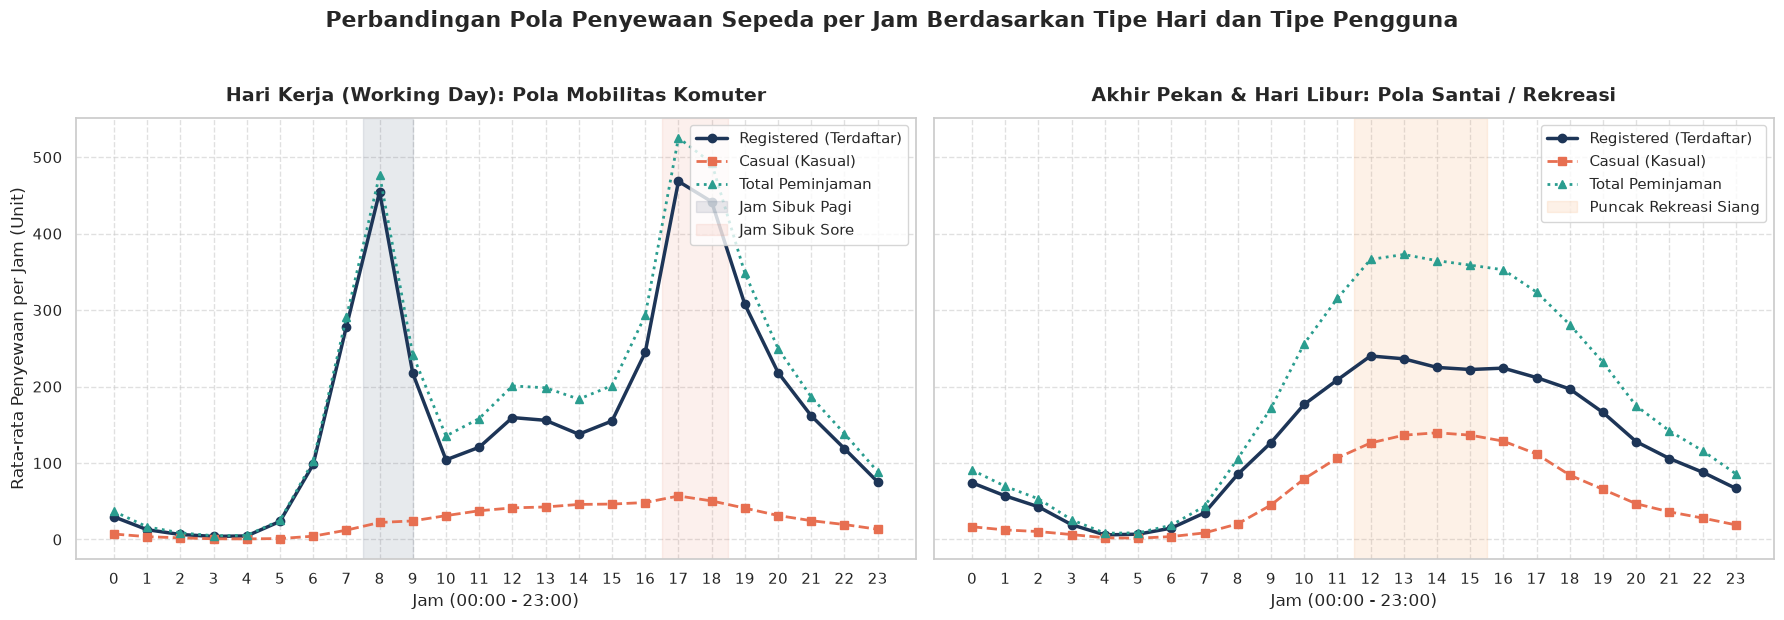

In [7]:
# Menyiapkan data agregasi rata-rata per jam untuk setiap tipe hari
hourly_daytype = hour_df.groupby(['workingday_label', 'hr'])[['casual', 'registered', 'cnt']].mean().reset_index()

# Visualisasi untuk Pertanyaan 2
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 6), sharey=True)

# Panel 1: Hari Kerja (Working Day)
data_work = hourly_daytype[hourly_daytype['workingday_label'] == 'Working Day']
axes[0].plot(data_work['hr'], data_work['registered'], marker='o', linewidth=2.5, color='#1D3557', label='Registered (Terdaftar)')
axes[0].plot(data_work['hr'], data_work['casual'], marker='s', linewidth=2, linestyle='--', color='#E76F51', label='Casual (Kasual)')
axes[0].plot(data_work['hr'], data_work['cnt'], marker='^', linewidth=2, linestyle=':', color='#2A9D8F', label='Total Peminjaman')

axes[0].set_title('Hari Kerja (Working Day): Pola Mobilitas Komuter', fontsize=14, fontweight='bold', pad=12)
axes[0].set_xlabel('Jam (00:00 - 23:00)', fontsize=12)
axes[0].set_ylabel('Rata-rata Penyewaan per Jam (Unit)', fontsize=12)
axes[0].set_xticks(range(0, 24))
axes[0].axvspan(7.5, 9, color='#1D3557', alpha=0.1, label='Jam Sibuk Pagi')
axes[0].axvspan(16.5, 18.5, color='#E76F51', alpha=0.1, label='Jam Sibuk Sore')
axes[0].legend(loc='upper right', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Panel 2: Akhir Pekan & Hari Libur (Weekend / Holiday)
data_weekend = hourly_daytype[hourly_daytype['workingday_label'] == 'Weekend/Holiday']
axes[1].plot(data_weekend['hr'], data_weekend['registered'], marker='o', linewidth=2.5, color='#1D3557', label='Registered (Terdaftar)')
axes[1].plot(data_weekend['hr'], data_weekend['casual'], marker='s', linewidth=2, linestyle='--', color='#E76F51', label='Casual (Kasual)')
axes[1].plot(data_weekend['hr'], data_weekend['cnt'], marker='^', linewidth=2, linestyle=':', color='#2A9D8F', label='Total Peminjaman')

axes[1].set_title('Akhir Pekan & Hari Libur: Pola Santai / Rekreasi', fontsize=14, fontweight='bold', pad=12)
axes[1].set_xlabel('Jam (00:00 - 23:00)', fontsize=12)
axes[1].set_xticks(range(0, 24))
axes[1].axvspan(11.5, 15.5, color='#F4A261', alpha=0.15, label='Puncak Rekreasi Siang')
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Perbandingan Pola Penyewaan Sepeda per Jam Berdasarkan Tipe Hari dan Tipe Pengguna', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Insight:**
1. **Analisis Visualisasi Pertanyaan 1 (Musim & Cuaca):**
   - **Musim Gugur (*Fall*)** merupakan musim dengan permintaan tertinggi (**5.644 unit/hari**), disusul oleh **Musim Panas (*Summer*)** (**4.992 unit/hari**) dan **Musim Dingin (*Winter*)** (**4.728 unit/hari**). Sementara **Musim Semi (*Spring*)** mencatatkan rata-rata terendah (**2.604 unit/hari**), yang menunjukkan bahwa temperatur yang terlalu dingin di awal tahun sangat membatasi aktivitas bersepeda.
   - **Kondisi Cuaca Cerah (*Clear/Partly Cloudy*)** menjadi kondisi prima dengan rata-rata **4.877 unit/hari**. Permintaan turun ke **4.036 unit/hari** pada kondisi berkabut/mendung, dan anjlok drastis ke **1.803 unit/hari** saat hujan atau salju ringan. Tidak ada aktivitas operasional harian yang tercatat pada cuaca buruk ekstrem.
2. **Analisis Visualisasi Pertanyaan 2 (Pola Jam & Tipe Pengguna):**
   - **Pola Komuter pada Hari Kerja (*Working Day*):** Menghasilkan kurva *bimodal* dengan dua lonjakan tajam pada jam berangkat kerja (pukul **08:00**, ~477 unit/jam) dan jam pulang kerja (pukul **17:00–18:00**, ~492–525 unit/jam). Pola ini hampir seluruhnya dikontribusikan oleh pengguna terdaftar (*registered*).
   - **Pola Rekreasi pada Akhir Pekan (*Weekend/Holiday*):** Menghasilkan kurva *unimodal* yang landai dengan puncak pada pukul **12:00–15:00** (mencapai ~370 unit/jam). Peminjaman oleh pengguna kasual (*casual*) meningkat lebih dari 2,5 kali lipat dibandingkan hari kerja pada jam-jam tersebut, menunjukkan pergeseran fungsi sepeda dari sarana transportasi komuter menjadi sarana hiburan/olahraga santai.

## Analisis Lanjutan (Opsional)

### Segmentasi Waktu Harian (*Dayparting Analysis*) & Analisis Kontribusi Tipe Pengguna

**Tujuan dan Penjelasan Teknik Analisis:**
1. **Latar Belakang & Tujuan:**
   Dalam operasional industri mobilitas perkotaan (*bike sharing*), fluktuasi permintaan sangat dinamis sepanjang 24 jam. Analisis per jam secara mentah (0–23) terkadang terlalu granular untuk kebijakan operasional tingkat manajerial. Oleh karena itu, diterapkan teknik **Analisis Segmentasi Waktu (*Dayparting Analysis / Time-of-Day Binning*)** untuk mengelompokkan jam ke dalam 5 fase operasional strategis:
   - **Dini Hari (00:00 – 05:59):** Jendela waktu mobilitas terendah untuk evaluasi pemeliharaan sepeda (*preventive maintenance*).
   - **Pagi (06:00 – 10:59):** Periode keberangkatan kerja dan sekolah (*morning commute*).
   - **Siang (11:00 – 14:59):** Periode mobilitas makan siang, bisnis antar-kantor, dan rekreasi santai.
   - **Sore (15:00 – 18:59):** Periode kepulangan komuter (*evening commute rush*).
   - **Malam (19:00 – 23:59):** Periode aktivitas santai malam dan kepulangan larut.

2. **Metodologi Analisis:**
   - Mengelompokkan data jam (`hr`) ke dalam 5 segmen diskrit.
   - Menghitung agregasi total peminjaman, rata-rata intensitas per jam, serta dekomposisi volume kontribusi pengguna kasual (*casual*) versus pengguna terdaftar (*registered*).
   - Memvisualisasikan hasil analisis menggunakan *Stacked Bar Chart* agar proporsi kontribusi masing-masing kelompok pengguna terlihat jelas.

Ringkasan Statistik Segmentasi Waktu (Dayparting):


,time_segment,total_casual,total_registered,total_cnt,rata_rata_per_jam
0,Dini Hari (00:00 - 05:59),19275,87234,106509,24.908559
1,Pagi (06:00 - 10:59),83062,672937,755999,208.092210
2,Siang (11:00 - 14:59),200806,495499,696305,239.033642
3,Sore (15:00 - 18:59),207156,850373,1057529,362.539938
4,Malam (19:00 - 23:59),109718,566619,676337,185.806868


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


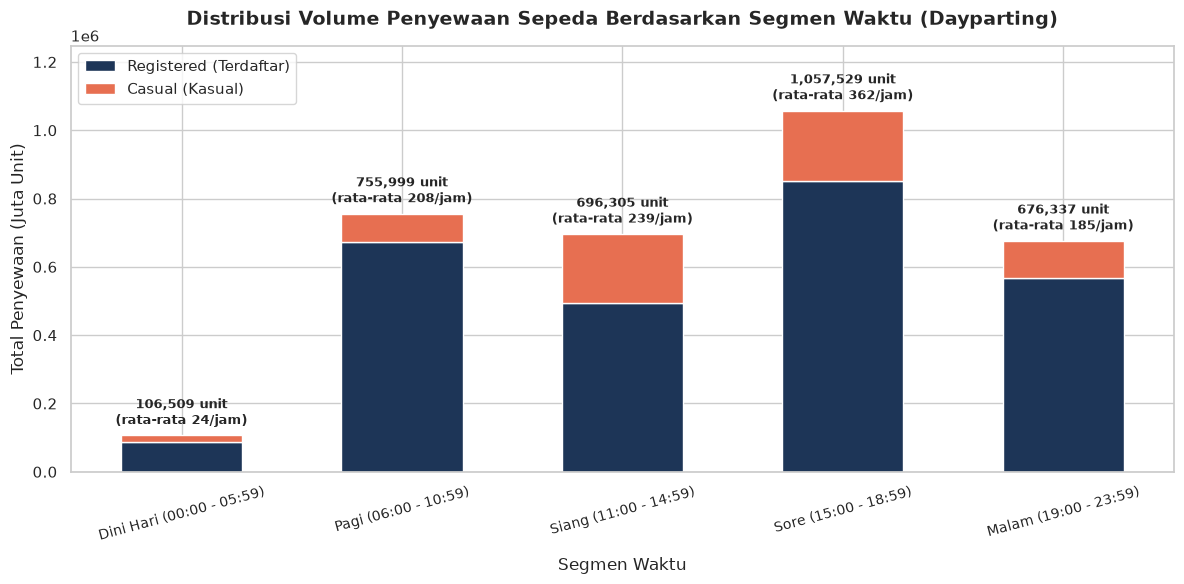

In [8]:
from IPython.display import display
# Analisis Lanjutan: Segmentasi Waktu Harian (Dayparting Analysis) & Kontribusi Pengguna

# 1. Definisi fungsi klasifikasi segmen waktu dalam sehari
def classify_time_of_day(hour):
    if 0 <= hour < 6:
        return 'Dini Hari (00:00 - 05:59)'
    elif 6 <= hour < 11:
        return 'Pagi (06:00 - 10:59)'
    elif 11 <= hour < 15:
        return 'Siang (11:00 - 14:59)'
    elif 15 <= hour < 19:
        return 'Sore (15:00 - 18:59)'
    else:
        return 'Malam (19:00 - 23:59)'

# Menambahkan kolom segmen waktu pada hour_df
hour_df['time_segment'] = hour_df['hr'].apply(classify_time_of_day)

# Urutan segmen kronologis
segment_order = [
    'Dini Hari (00:00 - 05:59)',
    'Pagi (06:00 - 10:59)',
    'Siang (11:00 - 14:59)',
    'Sore (15:00 - 18:59)',
    'Malam (19:00 - 23:59)'
]

segment_summary = hour_df.groupby('time_segment').agg(
    total_casual=('casual', 'sum'),
    total_registered=('registered', 'sum'),
    total_cnt=('cnt', 'sum'),
    rata_rata_per_jam=('cnt', 'mean')
).reindex(segment_order).reset_index()

print("Ringkasan Statistik Segmentasi Waktu (Dayparting):")
display(segment_summary)

# 2. Visualisasi Analisis Lanjutan: Stacked Bar Chart Kontribusi Segmen Waktu
fig, ax = plt.subplots(figsize=(12, 6))

x_pos = np.arange(len(segment_order))
bar_width = 0.55

bar_registered = ax.bar(
    x_pos, segment_summary['total_registered'],
    width=bar_width, label='Registered (Terdaftar)', color='#1D3557'
)
bar_casual = ax.bar(
    x_pos, segment_summary['total_casual'],
    bottom=segment_summary['total_registered'],
    width=bar_width, label='Casual (Kasual)', color='#E76F51'
)

ax.set_title('Distribusi Volume Penyewaan Sepeda Berdasarkan Segmen Waktu (Dayparting)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Segmen Waktu', fontsize=12, labelpad=10)
ax.set_ylabel('Total Penyewaan (Juta Unit)', fontsize=12)
ax.set_xticks(x_pos)
ax.set_xticklabels(segment_summary['time_segment'], fontsize=10, rotation=15)
ax.legend(loc='upper left', frameon=True)

# Tambahkan label total di atas setiap bar
for i, total in enumerate(segment_summary['total_cnt']):
    ax.annotate(
        f'{total:,} unit\n(rata-rata {int(segment_summary["rata_rata_per_jam"][i])}/jam)',
        (x_pos[i], total),
        ha='center', va='bottom', fontsize=9.5, fontweight='semibold',
        xytext=(0, 5), textcoords='offset points'
    )

ax.set_ylim(0, segment_summary['total_cnt'].max() * 1.18)
plt.tight_layout()
plt.show()

**Insight:**
- **Segmen Sore (15:00 – 18:59)** merupakan periode paling produktif dan tersibuk dalam sistem bike sharing, dengan total volume peminjaman mencapai **1.057.529 unit** dan rata-rata intensitas tertinggi yaitu **363 unit/jam**.
- **Segmen Pagi (06:00 – 10:59)** dan **Siang (11:00 – 14:59)** menyumbang volume signifikan masing-masing sebesar **755.999 unit** (rata-rata 208 unit/jam) dan **696.305 unit** (rata-rata 239 unit/jam).
- Kontribusi pengguna kasual (*casual*) memiliki proporsi terbesar pada **Segmen Siang** dan **Sore** (mencapai >200 ribu unit di masing-masing segmen), sedangkan pada Segmen Pagi didominasi mutlak oleh pengguna terdaftar (*registered*).
- Segmen **Dini Hari (00:00 – 05:59)** mencatat permintaan paling minim (**106.509 unit** atau rata-rata hanya 25 unit/jam), menjadikannya jendela waktu yang paling tepat dan ideal untuk melakukan perawatan unit sepeda (*maintenance*) serta redistribusi armada ke stasiun-stasiun komuter utama tanpa mengganggu pengguna.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:**
  1. Musim memiliki pengaruh yang sangat signifikan terhadap volume sewa sepeda: **Musim Gugur (*Fall*)** mencatat tingkat penyewaan tertinggi dengan rata-rata **5.644 unit/hari** (total 1.061.129 peminjaman), diikuti oleh **Musim Panas (*Summer*)** (**4.992 unit/hari**). Sebaliknya, **Musim Semi (*Spring*)** mencatat penyewaan terendah dengan rata-rata hanya **2.604 unit/hari** akibat cuaca dingin pasca-musim dingin.
  2. Kondisi cuaca menjadi penentu utama kenyamanan bersepeda: Kondisi **Cerah/Berawan Sebagian (*Clear/Partly Cloudy*)** mendominasi permintaan dengan rata-rata **4.877 unit/hari** (menyumbang 68,6% dari total peminjaman). Cuaca berkabut/mendung menurunkan permintaan menjadi **4.036 unit/hari**, dan cuaca presipitasi hujan/salju (*Light Snow/Rain*) menurunkan penyewaan secara drastis hingga **1.803 unit/hari** (turun >63%).

- **Conclusion pertanyaan 2:**
  1. Terdapat perbedaan perilaku mobilitas yang sangat kontras antara hari kerja dan akhir pekan:
     - Pada **Hari Kerja (*Working Day*)**, terjadi pola dua jam sibuk (*bimodal distribution*) pada pukul **08:00** pagi (rata-rata 477 unit/jam) dan pukul **17:00–18:00** sore (rata-rata 492–525 unit/jam), yang digerakkan oleh kebutuhan mobilitas komuter.
     - Pada **Akhir Pekan/Hari Libur (*Weekend/Holiday*)**, terjadi pola santai kurva tunggal (*unimodal*) dengan puncak di siang hari antara pukul **12:00 hingga 15:00** (rata-rata 358–373 unit/jam).
  2. Pengguna terdaftar (*registered*) merupakan tulang punggung bisnis dengan kontribusi **81,17%** dari total penyewaan dan sangat aktif di hari kerja. Pengguna kasual (*casual*) menyumbang **18,83%** dan aktivitasnya melonjak signifikan pada akhir pekan dan hari libur di siang hari untuk keperluan rekreasi.

**Rekomendasi Action Item:**
1. **Manajemen Armada Dinamis (*Dynamic Fleet Rebalancing*):**
   - Pada hari kerja, lakukan redistribusi unit sepeda sebelum pukul 07:30 ke stasiun-stasiun pemukiman/suburban menuju stasiun pusat bisnis (CBD), dan lakukan penarikan/rebalancing unit kembali ke area transit sebelum pukul 16:30.
   - Pada akhir pekan, fokuskan ketersediaan armada dan kapasitas dok di stasiun dekat taman, rute wisata rekreasi, dan pusat perbelanjaan mulai pukul 11:00 hingga sore.
2. **Optimalisasi Jadwal Perawatan Armada (*Preventive Maintenance Window*):**
   - Manfaatkan jendela waktu **Dini Hari (pukul 00:00 – 05:00)** untuk inspeksi teknis, perbaikan harian, dan pertukaran sepeda antar dok stasiun, karena aktivitas pengguna sangat rendah (<25 unit/jam).
   - Manfaatkan **Musim Semi awal (*Spring*)** dan periode musim dingin untuk melakukan peremajaan unit secara masif sebelum memasuki puncak permintaan di Musim Panas dan Gugur.
3. **Strategi Konversi Pengguna Kasual Menjadi Member (*Conversion Campaign*):**
   - Mengingat pengguna kasual sangat aktif di akhir pekan (mencapai >135 peminjaman/jam di siang hari), buat kampanye promosi khusus akhir pekan berupa diskon konversi langganan (misal *"Weekend Explorer Membership"* atau paket bulanan) untuk mengubah pengguna kasual menjadi anggota terdaftar loyal.
4. **Insentif Dinamis Berbasis Cuaca (*Weather-Triggered Dynamic Promotion*):**
   - Integrasikan sistem aplikasi dengan ramalan cuaca. Berikan diskon khusus atau reward poin ganda pada hari-hari dengan cuaca mendung/hujan ringan guna merangsang mobilitas dan mempertahankan volume peminjaman.